# Классификация тональности текстовых отзывов с использованием методов NLP

# Введение

Интернет-магазин запускает новый сервис. Теперь пользователи могут редактировать и дополнять описания товаров, как в вики-сообществах. То есть клиенты предлагают свои правки и комментируют изменения других. Магазину нужен инструмент, который будет искать токсичные комментарии и отправлять их на модерацию.

**Цель проекта**

Построить модель, которая будет классифицировать комментарии на позитивные и негативные.

**Данные**

`toxic_comments.csv` с признаками:

- text - текст комментариев
- toxic - целевой признак, где:
    - 1- комментарий негативный,
    - 0 - позитивный.

# Библиотеки

In [ ]:
# Встроенные модули Python
import re
import time

# Сторонние библиотеки для анализа данных и визуализации
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tqdm import tqdm
import numpy as np

# Обработка текста
import spacy
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords

try:
    stop_words = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))

from collections import Counter

# Работа с текстами
from sklearn.feature_extraction.text import TfidfVectorizer

# Модели
from sklearn.linear_model import LogisticRegression

# Метрики и оценка качества
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

# Валидация и пайплайны
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline

# Константа
RANDOM_STATE = 42

# Первичный обзор данных

Загружаем датасет:

In [ ]:
df = pd.read_csv('/kaggle/input/datasets/zdoronkov/toxic-comments/toxic_comments.csv')

Первичный обзор данных:

In [ ]:
df.head()

,Unnamed: 0,text,toxic
0,0,Explanation\nWhy the edits made under my usern...,0
1,1,D'aww! He matches this background colour I'm s...,0
2,2,"Hey man, I'm really not trying to edit war. It...",0
3,3,"""\nMore\nI can't make any real suggestions on ...",0
4,4,"You, sir, are my hero. Any chance you remember...",0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159292 entries, 0 to 159291
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  159292 non-null  int64 
 1   text        159292 non-null  object
 2   toxic       159292 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 3.6+ MB


Признак `Unnamed: 0` носит чисто технический характер и дублирует нумерацию строк. Удалим его перед дальнейшей обработкой:

In [ ]:
df = df.drop(columns=['Unnamed: 0'])

df.columns

Index(['text', 'toxic'], dtype='object')

**Выводы:**

- Данные успешно загружены и прочитаны. Датасет представляет собой таблицу, содержащую текстовые комментарии пользователей и бинарную разметку уровня токсичности.
- Выявлен и удален избыточный признак `Unnamed: 0`, дублирующий индексы строк и не несущий полезной информации для обучения моделей.
- В ходе анализа не обнаружено пропущенных значений (NaN) или явных дубликатов. Целостность данных сохранена.

# Исследовательский анализ данных

## Анализ целевого признака

Найдем соотношение положительных и отрицательных комментариев:

In [ ]:
toxic_pct = df['toxic'].value_counts(normalize=True).reset_index()
toxic_pct.columns = ['toxic', 'percent']
toxic_pct['percent'] = round(toxic_pct['percent']*100, 1)

toxic_pct

,toxic,percent
0,0,89.8
1,1,10.2


Построим график соотношения положительных и отрицательных комментариев:

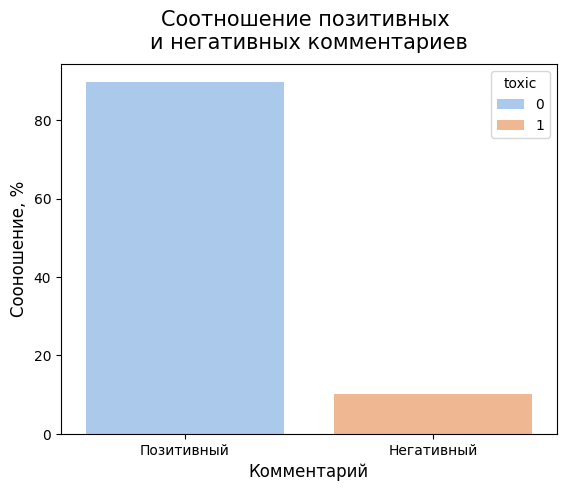

In [ ]:
sns.barplot(
    data=toxic_pct,
    x='toxic',
    y='percent',
    hue='toxic',
    palette='pastel'
)

plt.title('Соотношение позитивных \nи негативных комментариев', pad=11, fontsize=15)
plt.xlabel('Комментарий', fontsize=12)
plt.ylabel('Сооношение, %', fontsize=12)
plt.xticks([0, 1], labels=['Позитивный', 'Негативный']);

**Выводы:**

Данные показывают дисбаланс классов: позитивных отзывов в несколько раз больше положительных.

## Анализ текста

Изучим распреденение длины текста в комментариях:

In [ ]:
lens = df['text'].astype(str).str.len()
lens.describe()

count    159292.000000
mean        393.691303
std         590.111825
min           5.000000
25%          95.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: text, dtype: float64

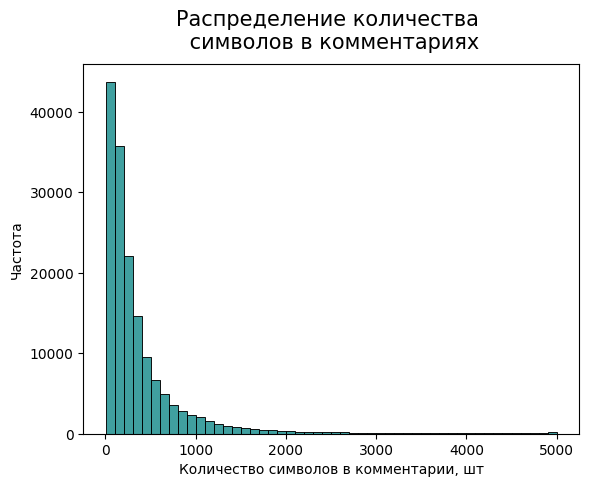

In [ ]:
# График распределения количеств символов в комментариях
sns.histplot(
    lens,
    bins=50,
    color='teal'
)
plt.xlabel('Количество символов в комментарии, шт')
plt.ylabel('Частота')
plt.title('Распределение количества \n символов в комментариях', pad=11, fontsize=15);

В датасете присутствуют короткие текстовые строки. Причем, чем короче комментарий, тем чаще он встречается в датасете.

Выведем примеры таких коротких комметариев:

In [ ]:
# Вывод текста с длинной от 0 до 15 символов
df['text'][(lens >= 0) & (lens < 15)]

3631      September 2008
10193     64.86.141.133"
15432            Howdy!"
20550     September 2015
38743      88.104.31.21"
52336             14:53,
93421       {{unblock|yo
100520    hello cow head
101306     GONE FISHING.
109794          {{unbloc
118650          FUCK YOU
119018               """
120868          you suck
136820            ~ J.Lo
137400            == """
141644    Unblock Please
150648      04:59, 22 Au
Name: text, dtype: object

Среди коротких комментариев встречаются даты, приветствия и технические заголовки. Часть комментариев имеет негативных оттенок.

**Выводы:**

- Текстовые данные содержат как стандартные слова, так и различные символы, числовые маркеры и даты. Это потребует предварительной очистки регулярными выражениями.

- Поскольку анализируемый датасет состоит из комментариев на английском языке, для очистки текста от неинформативного шума будет использоваться стандартный англоязычный пакет стоп-слов из библиотеки NLTK.

# Подготовка текстов

Перед векторизаций текста важно привести слова к начальной форме, убрать пунктуацию и стоп-слова. Сделаем это с помощью библиотеки spaCy:

In [ ]:
# Загрузка модели
nlp = spacy.load(
    'en_core_web_sm',
    disable=['parser', 'ner'] # отключаем ненужные модули
)

# Обработка текста
docs = nlp.pipe(
    df['text'].astype(str),
    batch_size=1000,
    n_process=-1
)

# Функция извлечения чистых лемм из одного doc-объекта
def process_doc(doc):
    lemmas = []
    for token in doc:
        if token.is_alpha: # отбираем токены из букв
            lemmas.append(token.lemma_.lower()) # приводим леммы к нижнему регистру
    return " ".join(lemmas)

# Сохранение результата в датафрейм
df['clean_text'] = [process_doc(doc) for doc in tqdm(docs, total=len(df))]

100%|██████████| 159292/159292 [06:46<00:00, 392.33it/s] 


Визализируем топ 150 слов из негативных комментариев:

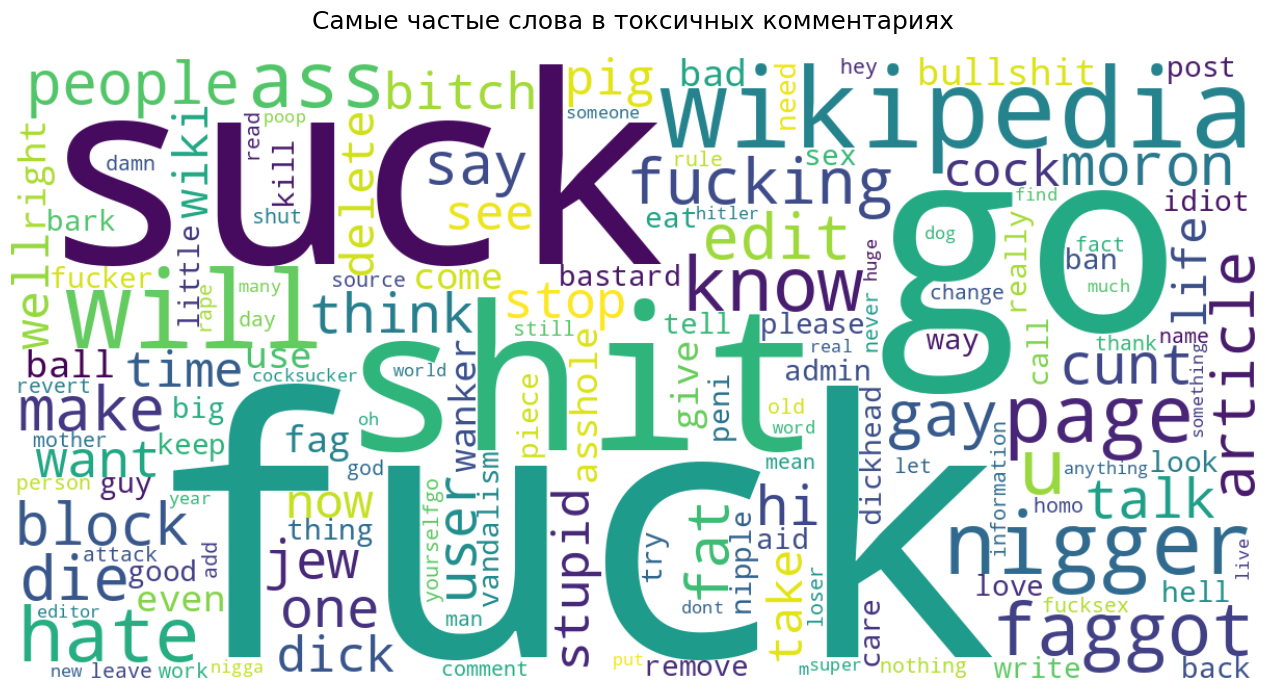

In [ ]:
# Отбираем негативные комментарии
toxic_texts = df[df['toxic'] == 1]['clean_text'].astype(str)

# Объединяем в одну строку
text_raw = " ".join(toxic_texts)

# Настройка и генерация облака слов
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=150,
    collocations=False,
    random_state=RANDOM_STATE
).generate(text_raw)

# Отрисовка
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Самые частые слова в токсичных комментариях', fontsize=18, pad=20)
plt.tight_layout()
plt.show()

Среди ненормативной лексики встречаются слова, которы не несут эмоциональной окраски.

# Моделирование

## Обучение

Разделим данны на обучающую и тестовую выборки:

In [ ]:
X = df['clean_text']
y = df['toxic']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, # на тестовую выборку пойдёт 20% данных
    stratify=y, # учитываем дисбаланс целевого признака
    random_state=RANDOM_STATE
)

**Векторизация текста:**

Для преобразования текстовых данных в числовые вектора применим метод `TF-IDF`.

**Метрика:**

Заказчику важно, чтобы модель находила как можно больше негативных комметариев и давала как можно меньше ложноположительных результатов (принимала нейтральные комментарии за негативные). Для данной задачи подходит метрика `F1-score`.

**Модель:**

Для мешка слов (TF-IDF) лучше всего подходят линейная модель (LogisticRegression), так как она эффективно и быстро работают с огромными разреженными матрицами.


In [ ]:
# Сборка пайплайна
pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    (
        'clf',
        LogisticRegression(
            class_weight='balanced',
            random_state=42,
            max_iter=500,
        ),
    ),
])

# Сетка гиперпараметров
param_grid = {
    'clf__C': [1.0, 10.0, 15.0],
}

# Перебор гиперпараметров и кросс-валидация
model = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    verbose=2,
    n_jobs=-1,
)

# Обучение модели
model.fit(X_train, y_train)

# Вывод результатов
best_idx = model.best_index_
std_f1 = model.cv_results_['std_test_score'][best_idx]

print(f"Оптимальные параметры: {model.best_params_}")
print(f"Лучшее значение метрики F1: {model.best_score_:.4f}")
print(f"Стандартное отклонение F1: {std_f1:.4f}")

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Оптимальные параметры: {'clf__C': 15.0}
Лучшее значение метрики F1: 0.7873
Стандартное отклонение F1: 0.0027


Модель валидирована. F1 = `0.7873`. Низкое стандартное отклонение = `0.0027` говорит о стабильности предсказательной способности модели.

## Тестирование

Оценим работу модели на заранее отведенной тестовой выборке:

In [ ]:
# Предсказание на тестовой выборке
y_pred = model.predict(X_test)

# Значение метрики F1 на тестовой выборке
final_f1 = f1_score(y_test, y_pred)
print(f"Финальный F1-score на тестовой выборке: {final_f1:.4f}")

Финальный F1-score на тестовой выборке: 0.8007


Результат получился даже выше, чем это было на тренировочной выборке. Визуализируем результаты с помощью ConfusionMatrix:

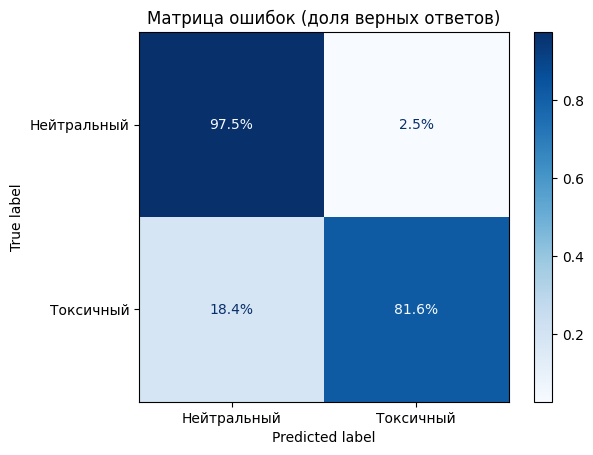

In [ ]:
labels = ['Нейтральный', 'Токсичный']

disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=labels,
    cmap='Blues',
    normalize='true',
    values_format='.1%'
)
plt.title('Матрица ошибок (доля верных ответов)')
plt.show()

**Выводы:**

Минимум ложных блокировок (2.5%): Модель практически не наказывает адекватных пользователей — 97.5% нормального контента корректно пропускается.

Эффективность модерации (81.6%): Модель успешно отлавливает более 80% нарушений, автоматизируя львиную долю рутины.

Пропуск токсичности (18.4%): Почти каждая пятая токсичная реплика просачивается через фильтр.

# Выводы

1. **Краткое резюме**

Разработана ML-модель на базе логистической регрессии для автоматической классификации пользовательских комментариев на позитивные/нейтральные и токсичные. Модель успешно автоматизирует модерацию правок в описаниях товаров, отлавливая более 80% нарушений.

2. **Бизнес инсайты**

    - **Эффективность модерации:** Автоматическое обнаружение 81.6% токсичных комментариев позволяет снять основной объем рутинной нагрузки с модераторов платформы.
    
    - **Сохранение лояльности аудитории:** Модель обладает крайне низкой долей ложных срабатываний (False Positive = 2.5%). Адекватный контент пользователей пропускается в 97.5% случаев, что предотвращает отток лояльной аудитории и защищает службу поддержки от жалоб на ошибочные баны.
    
    - **Управление репутацией:** Около 18.4% нарушений (False Negative) фильтр пока пропускает. Для крупной публичной платформы это несет определенные репутационные риски и требует донастройки бизнес-логики применения модели.

3. **Технические результаты**

    - **Качество и подготовка данных:** Обработан датасет из 159 292 записей (без пропусков, удален технический столбец `Unnamed: 0`). Проведена базовая очистка текста от небуквенных символов, приведение к нижнему регистру и лемматизация с использованием `spaCy`. Векторизация признаков выполнена с помощью `TfidfVectorizer`.
    
    - **Моделирование:** Учтен сильный дисбаланс целевого признака (89.8% к 10.2% в пользу позитивного класса), что обусловило выбор метрики $F_1$-score. Обучение логистической регрессии проведено в рамках единого пайплайна с подбором оптимальных гиперпараметров через `GridSearchCV`.

4. **Ограничения и зоны роста**

Для снижения доли пропущенного токсичного контента платформе рекомендуется внедрить гибридную систему модерации:
- **Калибровка порога:** Смещение порога классификации с дефолтных $0.5$ до $0.3$–$0.35$. Это позволит отлавливать больше токсичности ценой контролируемого роста ложных блокировок.
- **Внедрение «серой зоны»:** Комментарии, в которых модель не до конца уверена (вероятность токсичности в диапазоне $0.25$–$0.70$), целесообразно направлять на проверку живым операторам. Полярные значения (ниже $0.25$ и выше $0.70$) можно смело отдавать на автопубликацию и автобан соответственно.